# Demo 2: Neural Operators, Learning to Solve a PDE Once for All Initial Conditions

**From Equation to World Models: AI and the Simulation of Physics** · SIET talk

The PINN in Demo 1 learned **one** solution. A **neural operator** learns the whole **solution operator**, the map

$$\mathcal G:\; u(x, 0) \;\longmapsto\; u(x, T)$$

Train it once on simulations, and it predicts the outcome for a **new** initial condition in about a millisecond.

We use the **Fourier Neural Operator (FNO)** (Li et al., 2021) on the viscous **Burgers equation**, a 1-D cousin of Navier–Stokes that forms shock-like fronts:

$$\frac{\partial u}{\partial t} + u\frac{\partial u}{\partial x} = \nu\frac{\partial^2 u}{\partial x^2},\qquad x\in[0,2\pi)\ \text{periodic},\ \nu = 0.05$$

Plan:
1. Generate training data with a classical numerical solver (the "old way").
2. Build an FNO from scratch in PyTorch (about 40 lines).
3. Train it (about 1 minute on a laptop CPU).
4. Compare accuracy and speed, and try **zero-shot super-resolution**.

In [1]:
import os, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import clear_output

torch.manual_seed(0)
device = "cpu"          # the model is small; the CPU is fast and avoids complex-FFT gaps on Apple MPS
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

NU, T_FINAL, N = 0.05, 1.0, 256
DATA_FILE, MODEL_FILE = "burgers_data.npz", "fno_burgers.pt"

---
## 1. The classical way: a pseudo-spectral solver

We go to Fourier space, treat the diffusion term exactly, and step the nonlinear term forward with a 4th-order Runge–Kutta scheme (integrating-factor RK4) using 1,000 small time steps. This is what the network will learn to replace.

In [2]:
def random_initial_condition(n_samples, N, rng, n_modes=8, amp=1.5):
    # Smooth random periodic functions: a random sum of the first few sine/cosine modes
    x = np.linspace(0, 2 * np.pi, N, endpoint=False)
    k = np.arange(1, n_modes + 1)
    a = rng.normal(size=(n_samples, n_modes)) / k ** 1.5
    b = rng.normal(size=(n_samples, n_modes)) / k ** 1.5
    u = a @ np.cos(np.outer(k, x)) + b @ np.sin(np.outer(k, x))
    return x, amp * u / np.abs(u).max(axis=1, keepdims=True)


def solve_burgers(u0, nu=NU, T=T_FINAL, dt=1e-3, n_save=0):
    # Integrating-factor RK4 pseudo-spectral solver, vectorised over a batch of initial conditions
    Nx = u0.shape[-1]
    k = np.fft.rfftfreq(Nx, d=1.0 / Nx)          # integer wavenumbers
    L = -nu * k ** 2                              # diffusion, handled exactly
    dealias = k < (2 / 3) * (Nx / 2)
    E, E2 = np.exp(dt * L), np.exp(dt * L / 2)

    def nonlinear(uh):                            # -(u^2/2)_x in Fourier space
        u = np.fft.irfft(uh, n=Nx)
        return -0.5j * k * np.fft.rfft(u * u) * dealias

    uh = np.fft.rfft(u0)
    steps = int(round(T / dt))
    snaps, every = [u0.copy()], (steps // n_save if n_save else None)
    for s in range(steps):
        k1 = nonlinear(uh)
        k2 = nonlinear(E2 * (uh + dt / 2 * k1))
        k3 = nonlinear(E2 * uh + dt / 2 * k2)
        k4 = nonlinear(E * uh + dt * E2 * k3)
        uh = E * uh + dt / 6 * (E * k1 + 2 * E2 * (k2 + k3) + k4)
        if every and (s + 1) % every == 0:
            snaps.append(np.fft.irfft(uh, n=Nx))
    u = np.fft.irfft(uh, n=Nx)
    return (u, np.array(snaps)) if n_save else u

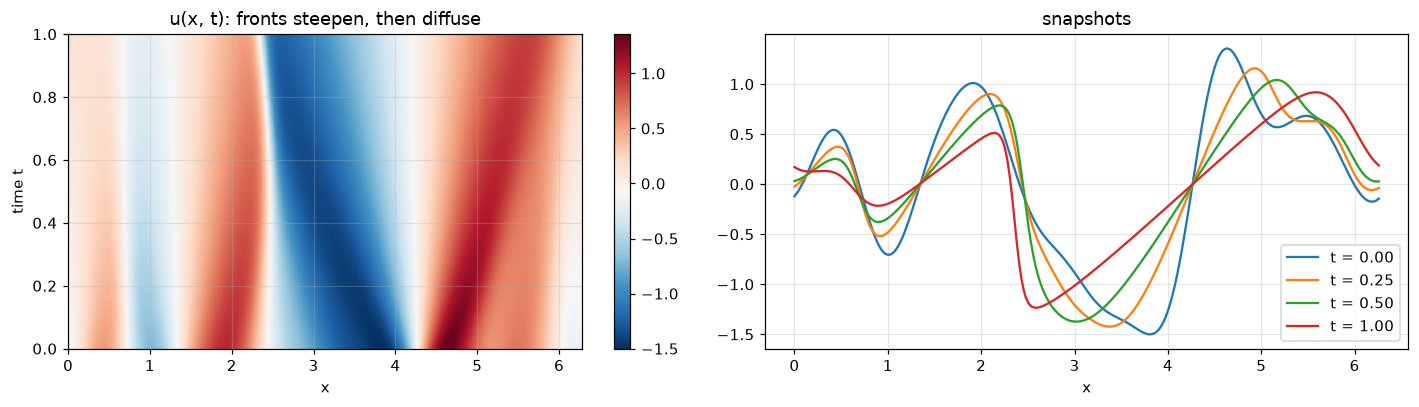

In [3]:
# Look at one simulation in space-time
rng = np.random.default_rng(42)
x, u0_demo = random_initial_condition(1, N, rng)
uT_demo, snaps = solve_burgers(u0_demo, n_save=100)
snaps = snaps[:, 0]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
im = ax[0].imshow(snaps, aspect="auto", origin="lower", extent=[0, 2 * np.pi, 0, T_FINAL], cmap="RdBu_r")
ax[0].set_xlabel("x"); ax[0].set_ylabel("time t"); ax[0].set_title("u(x, t): fronts steepen, then diffuse"); plt.colorbar(im, ax=ax[0])
for i in [0, 25, 50, 100]:
    ax[1].plot(x, snaps[i], label=f"t = {i / 100:.2f}")
ax[1].set_xlabel("x"); ax[1].legend(); ax[1].set_title("snapshots")
plt.tight_layout(); plt.show()

In [4]:
# Generate the dataset (cached to disk so the live demo is instant the second time)
N_TRAIN, N_TEST = 1000, 200
if os.path.exists(DATA_FILE):
    d = np.load(DATA_FILE); u0_all, uT_all = d["u0"], d["uT"]
    print("loaded cached dataset", u0_all.shape)
else:
    rng = np.random.default_rng(0)
    _, u0_all = random_initial_condition(N_TRAIN + N_TEST, N, rng)
    t0 = time.time()
    uT_all = solve_burgers(u0_all)
    print(f"solved {len(u0_all)} PDEs with the classical solver in {time.time() - t0:.1f} s")
    np.savez_compressed(DATA_FILE, u0=u0_all, uT=uT_all)

u0_t = torch.tensor(u0_all, dtype=torch.float32)
uT_t = torch.tensor(uT_all, dtype=torch.float32)
train_in, train_out = u0_t[:N_TRAIN], uT_t[:N_TRAIN]
test_in, test_out = u0_t[N_TRAIN:], uT_t[N_TRAIN:]
print("training tensor shapes:", tuple(train_in.shape), "->", tuple(train_out.shape))

solved 1200 PDEs with the classical solver in 14.8 s


training tensor shapes: (1000, 256) -> (1000, 256)


---
## 2. The Fourier Neural Operator

The key idea is to do the "learning" in **Fourier space**. Each Fourier layer:

1. transforms the signal with the FFT: $\hat v_k = \mathcal F[v]_k$,
2. multiplies the lowest $k_{\max}$ modes by a **learned complex tensor** $R_k \in \mathbb C^{c\times c}$ (this is a tensor contraction, `einsum("bik,iok->bok")`),
3. transforms back and adds a local linear term: $\;v \leftarrow \sigma\big(\mathcal F^{-1}[R\cdot\hat v] + Wv\big)$.

Because the weights live on Fourier *modes* and not on grid points, the same trained network works on **any grid resolution**.

Why keeping only a few modes is enough: most of the information in a smooth physical field sits in the low frequencies.

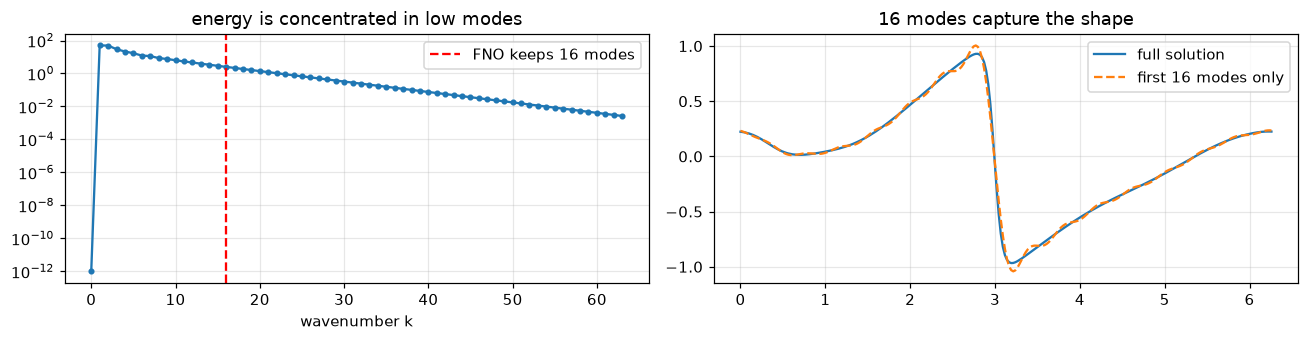

In [5]:
u = u0_all[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].semilogy(np.abs(np.fft.rfft(uT_all[0]))[:64] + 1e-12, "o-", ms=3)
ax[0].axvline(16, color="r", ls="--", label="FNO keeps 16 modes"); ax[0].set_xlabel("wavenumber k")
ax[0].set_title("energy is concentrated in low modes"); ax[0].legend()
uh = np.fft.rfft(uT_all[0]); uh[16:] = 0
ax[1].plot(x, uT_all[0], label="full solution"); ax[1].plot(x, np.fft.irfft(uh, n=N), "--", label="first 16 modes only")
ax[1].legend(); ax[1].set_title("16 modes capture the shape")
plt.tight_layout(); plt.show()

In [6]:
class SpectralConv1d(nn.Module):
    # Fourier layer: FFT -> multiply low modes by learned complex weights -> inverse FFT
    def __init__(self, in_ch, out_ch, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / (in_ch * out_ch)
        self.weight = nn.Parameter(scale * torch.randn(in_ch, out_ch, modes, dtype=torch.cfloat))

    def forward(self, v):                          # v: (batch, channels, n_points)
        n = v.shape[-1]
        v_hat = torch.fft.rfft(v)                  # (batch, channels, n//2+1), complex
        out_hat = torch.zeros(v.shape[0], self.weight.shape[1], n // 2 + 1, dtype=torch.cfloat, device=v.device)
        m = min(self.modes, n // 2 + 1)
        out_hat[:, :, :m] = torch.einsum("bik,iok->bok", v_hat[:, :, :m], self.weight[:, :, :m])
        return torch.fft.irfft(out_hat, n=n)


class FNO1d(nn.Module):
    def __init__(self, modes=16, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)                               # (u0(x), x) -> width channels
        self.spectral = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.local = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.project = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))

    def forward(self, u0, verbose=False):          # u0: (batch, n_points)
        n = u0.shape[-1]
        grid = torch.linspace(0, 1, n + 1, device=u0.device)[:-1].expand(u0.shape[0], n)
        v = self.lift(torch.stack([u0, grid], dim=-1))                # (batch, n, width)
        v = v.permute(0, 2, 1)                                        # (batch, width, n)
        if verbose: print("after lifting     ", tuple(v.shape))
        for i, (spec, loc) in enumerate(zip(self.spectral, self.local)):
            v = spec(v) + loc(v)
            if i < len(self.spectral) - 1:
                v = F.gelu(v)
            if verbose: print(f"after Fourier layer {i + 1}", tuple(v.shape))
        out = self.project(v.permute(0, 2, 1)).squeeze(-1)            # (batch, n)
        if verbose: print("output            ", tuple(out.shape))
        return out


model = FNO1d().to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")
_ = model(train_in[:4], verbose=True)

parameters: 287,425
after lifting      (4, 64, 256)
after Fourier layer 1 (4, 64, 256)
after Fourier layer 2 (4, 64, 256)
after Fourier layer 3 (4, 64, 256)
after Fourier layer 4 (4, 64, 256)
output             (4, 256)


---
## 3. Training

Loss = relative $L^2$ error, $\;\|\hat u - u\|_2 / \|u\|_2$, averaged over the batch. If a trained model is already saved, we load it; delete `fno_burgers.pt` to train live.

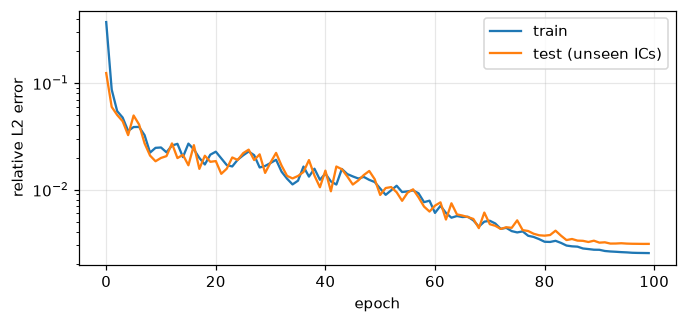

epoch  99  train 0.0025  test 0.0031  (461 s)


In [7]:
def rel_l2(pred, true):
    return (torch.linalg.norm(pred - true, dim=-1) / torch.linalg.norm(true, dim=-1)).mean()

EPOCHS, BATCH = 100, 20
if os.path.exists(MODEL_FILE):
    model.load_state_dict(torch.load(MODEL_FILE, map_location=device))
    print("loaded trained model from", MODEL_FILE)
else:
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    train_hist, test_hist = [], []
    t0 = time.time()
    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(N_TRAIN)
        running = 0.0
        for i in range(0, N_TRAIN, BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = rel_l2(model(train_in[idx]), train_out[idx])
            loss.backward(); opt.step()
            running += loss.item() * len(idx)
        sched.step()
        model.eval()
        with torch.no_grad():
            test_err = rel_l2(model(test_in), test_out).item()
        train_hist.append(running / N_TRAIN); test_hist.append(test_err)
        if epoch % 10 == 0 or epoch == EPOCHS - 1:
            clear_output(wait=True)
            plt.figure(figsize=(7, 3)); plt.semilogy(train_hist, label="train"); plt.semilogy(test_hist, label="test (unseen ICs)")
            plt.xlabel("epoch"); plt.ylabel("relative L2 error"); plt.legend(); plt.show()
            print(f"epoch {epoch:3d}  train {train_hist[-1]:.4f}  test {test_err:.4f}  ({time.time() - t0:.0f} s)")
    torch.save(model.state_dict(), MODEL_FILE)
model.eval();

---
## 4. Results

### Accuracy on initial conditions the network has never seen

mean relative L2 error on 200 unseen test cases: 0.31 %


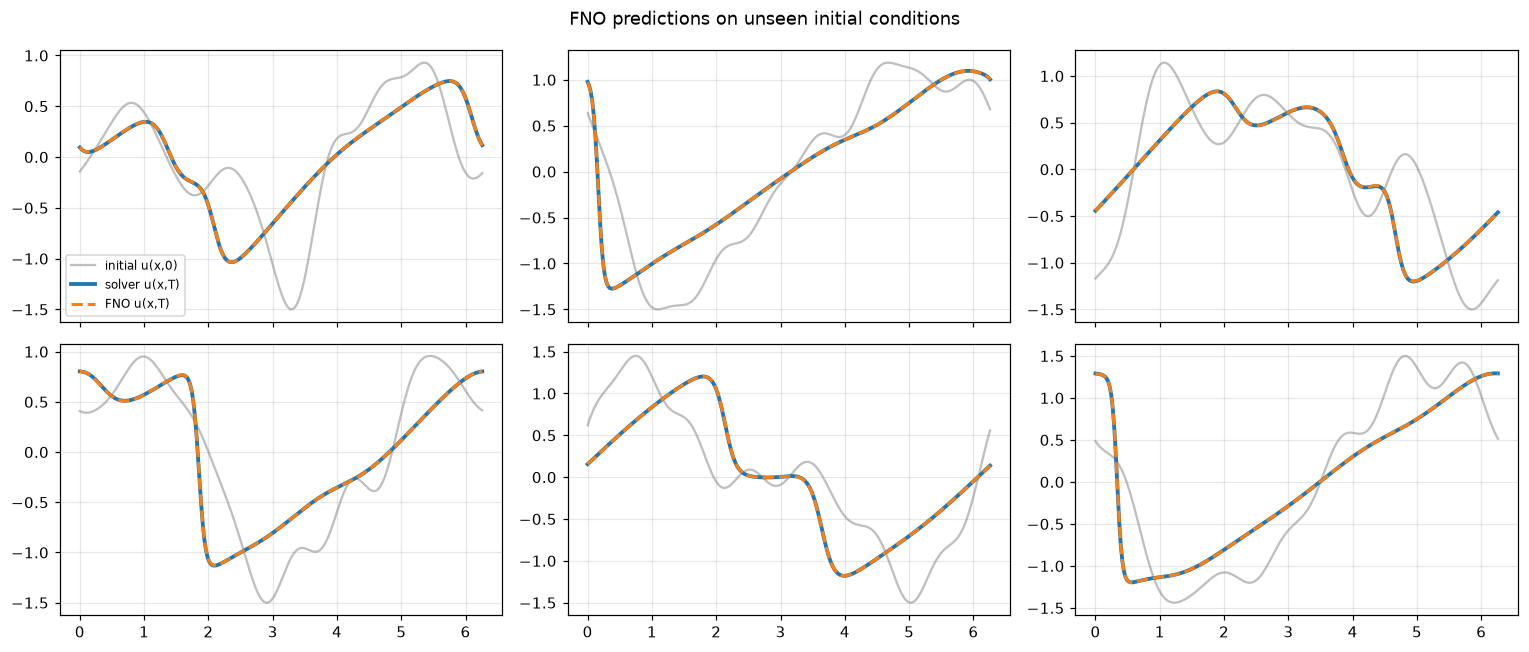

In [8]:
with torch.no_grad():
    pred_test = model(test_in)
print(f"mean relative L2 error on {N_TEST} unseen test cases: {rel_l2(pred_test, test_out).item() * 100:.2f} %")

fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for ax, i in zip(axes.flat, [0, 7, 21, 42, 99, 150]):
    ax.plot(x, test_in[i], color="gray", alpha=0.5, label="initial u(x,0)")
    ax.plot(x, test_out[i], lw=2.5, label="solver u(x,T)")
    ax.plot(x, pred_test[i], "--", lw=2, label="FNO u(x,T)")
axes[0, 0].legend(fontsize=8); fig.suptitle("FNO predictions on unseen initial conditions"); plt.tight_layout(); plt.show()

### Speed: classical solver vs neural operator

In [9]:
batch = u0_all[N_TRAIN:]
t0 = time.time(); _ = solve_burgers(batch); t_solver = time.time() - t0
t0 = time.time()
with torch.no_grad():
    _ = model(torch.tensor(batch, dtype=torch.float32))
t_fno = time.time() - t0
print(f"{len(batch)} simulations   classical solver: {t_solver:.2f} s    FNO: {t_fno * 1000:.1f} ms    speed-up ≈ {t_solver / t_fno:,.0f}x")

200 simulations   classical solver: 1.50 s    FNO: 260.9 ms    speed-up ≈ 6x


> This 1-D solver is already very cheap. For 3-D turbulence, weather or plasma simulations that take hours on a supercomputer, surrogates like this give speed-ups of 1,000x to 100,000x. That makes things like real-time control, uncertainty quantification with thousands of runs, and design optimisation practical.

### Zero-shot super-resolution

The FNO was trained **only on 256-point grids**. Because it works on Fourier modes, we can feed it a **1024-point** grid it has never seen.

error on the training resolution (256): 0.42 %    on an unseen resolution (1024): 0.42 %


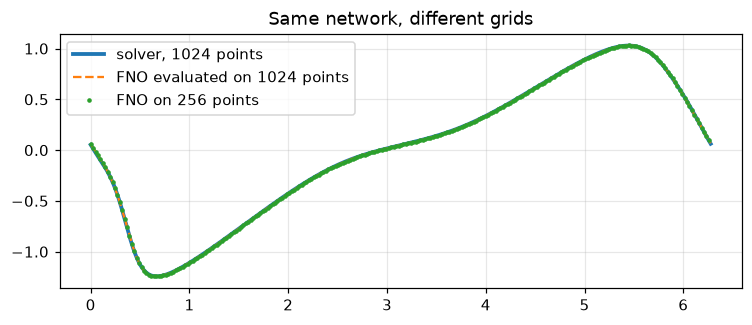

In [10]:
rng = np.random.default_rng(7)
x_hr, u0_hr = random_initial_condition(20, 1024, rng)
uT_hr = solve_burgers(u0_hr)

with torch.no_grad():
    pred_hr = model(torch.tensor(u0_hr, dtype=torch.float32))                  # 1024 points
    pred_lr = model(torch.tensor(u0_hr[:, ::4].copy(), dtype=torch.float32))   # 256 points
e_hr = rel_l2(pred_hr, torch.tensor(uT_hr, dtype=torch.float32)).item()
e_lr = rel_l2(pred_lr, torch.tensor(uT_hr[:, ::4].copy(), dtype=torch.float32)).item()
print(f"error on the training resolution (256): {e_lr * 100:.2f} %    on an unseen resolution (1024): {e_hr * 100:.2f} %")

plt.figure(figsize=(8, 3))
plt.plot(x_hr, uT_hr[0], lw=2.5, label="solver, 1024 points")
plt.plot(x_hr, pred_hr[0], "--", label="FNO evaluated on 1024 points")
plt.plot(x_hr[::4], pred_lr[0], ".", ms=4, label="FNO on 256 points")
plt.legend(); plt.title("Same network, different grids"); plt.show()

### Try your own initial condition (live)

Edit the function below. For example, try a sharp bump, a square wave, or `np.sin(3*x)`. Note that anything very different from the training data (non-zero mean, much larger amplitude) is **out of distribution**, and the network will degrade. That is an honest limitation to show the audience.

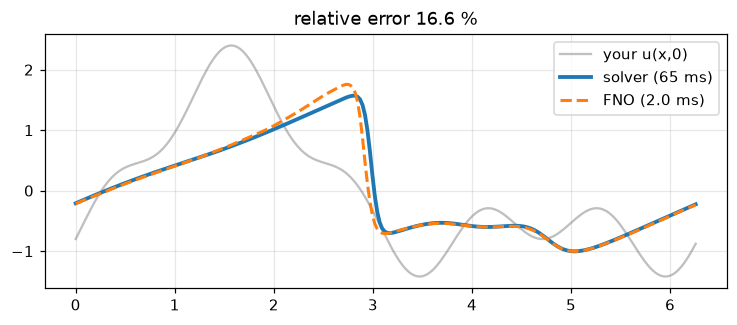

In [11]:
def my_initial_condition(x):
    return 1.2 * np.sin(x) - 0.8 * np.cos(2 * x) + 0.4 * np.sin(5 * x)
    # return 1.5 * np.exp(-8 * (x - np.pi) ** 2) - 1.5 * np.exp(-8 * (x - np.pi) ** 2).mean()   # a bump
    # return 1.0 * np.sign(np.sin(x))                                                           # square wave (hard!)

u0_mine = my_initial_condition(x)[None, :]
t0 = time.time(); uT_mine = solve_burgers(u0_mine)[0]; ts = time.time() - t0
t0 = time.time()
with torch.no_grad():
    pred_mine = model(torch.tensor(u0_mine, dtype=torch.float32))[0]
tf = time.time() - t0

err = np.linalg.norm(pred_mine.numpy() - uT_mine) / np.linalg.norm(uT_mine)
plt.figure(figsize=(8, 3))
plt.plot(x, u0_mine[0], color="gray", alpha=0.5, label="your u(x,0)")
plt.plot(x, uT_mine, lw=2.5, label=f"solver ({ts * 1000:.0f} ms)")
plt.plot(x, pred_mine, "--", lw=2, label=f"FNO ({tf * 1000:.1f} ms)")
plt.legend(); plt.title(f"relative error {err * 100:.1f} %"); plt.show()

### Takeaways

* A **neural operator** learns a map between *functions*, not just between numbers, so it generalises across initial conditions.
* The FNO is built from tensor algebra: FFT, then a complex tensor contraction, then an inverse FFT.
* Train once (expensive), then infer in milliseconds (cheap). This is the idea behind AI weather models such as FourCastNet, GraphCast and Aurora.
* Limitations: it needs lots of simulation data, it degrades out of distribution, and it does not automatically conserve physical quantities. Hybrid physics+AI models are an active research area.

Next, **Demo 3**: what if we skip the equations entirely and learn physics from **video**?